# Week 04 · City Trips: простая практика визуализации
**BrainCode Academy · ML & AI · Assylbek Gizatov**

Один небольшой шаг за раз: сначала таблица, затем график, затем вывод. Те же темы: проверка данных, распределения, сравнение зон, scatter, Pearson/Spearman, доли, временной график, CSV/PNG. ECDF и Plotly остаются необязательными бонусами.

Данные встроены: синтетические заявки за 5–11 октября 2026, не статистика реального города. Одна строка = одна заявка. Отмена не равна поездке с нулевой длительностью.

**Запуск:** выполняйте ячейки сверху вниз через Shift+Enter. Основная практика требует pandas, matplotlib, seaborn, scipy; бонус — plotly. При необходимости в отдельной ячейке выполните `%pip install pandas matplotlib seaborn scipy plotly`. Для просмотра данных интернет не нужен.

**Простые обозначения:** `=` сохранить результат; `==` сравнить; `таблица["колонка"]` выбрать столбец; `()` вызвать команду; `#` комментарий. `plt` работает с текущим рисунком: перед новым графиком всегда вызываем `plt.figure()`.


## 1. Подготовка
Импортируем инструменты. Выходные файлы появятся в папке `week04_outputs` рядом с рабочей папкой ноутбука.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
from pathlib import Path
import json
from IPython.display import display
sns.set_theme(style="whitegrid")
output = Path("week04_outputs")
output.mkdir(exist_ok=True)


## Встроенные данные
Следующую ячейку просто выполните. Длинный текст внутри кавычек — записи данных, а не сложный алгоритм. Столбцы: ID, время, зона, канал, статус, расстояние (км), длительность (мин), стоимость (₸).

In [2]:
TRIPS_CSV = 'trip_id,requested_at,zone_id,channel,status,distance_km,duration_min,fare_kzt\n1001,2026-10-05 06:00,Z01,app,cancelled,,,\n1002,2026-10-05 06:30,Z03,phone,completed,3.0,12.7,1100\n1003,2026-10-05 07:00,Z02,app,completed,15.8,56.2,3450\n1004,2026-10-05 07:30,Z03,app,completed,11.8,32.6,2650\n1005,2026-10-05 08:00,Z01,phone,completed,9.7,28.7,2250\n1006,2026-10-05 08:30,Z05,web,completed,15.1,59.4,3150\n1007,2026-10-05 09:00,Z04,,completed,10.5,28.7,2450\n1008,2026-10-05 09:30,Z04,app,completed,1.6,9.2,800\n1009,2026-10-05 10:00,Z01,phone,cancelled,,,\n1010,2026-10-05 10:30,Z03,phone,completed,8.6,,2050\n1011,2026-10-05 11:00,Z02,app,completed,15.8,53.8,3400\n1012,2026-10-05 11:30,Z03,app,completed,5.1,13.5,1500\n1013,2026-10-05 12:00,Z03,app,completed,13.6,39.4,2900\n1014,2026-10-05 12:30,Z04,app,completed,13.3,47.2,2950\n1015,2026-10-05 13:00,Z01,app,completed,18.5,59.1,3900\n1016,2026-10-05 13:30,Z02,phone,completed,8.7,25.1,1950\n1017,2026-10-05 14:00,Z01,phone,cancelled,,,\n1018,2026-10-05 14:30,Z05,phone,cancelled,,,\n1019,2026-10-05 15:00,Z05,app,completed,4.7,19.4,1450\n1020,2026-10-05 15:30,Z04,phone,completed,10.9,44.6,2450\n1021,2026-10-05 16:00,Z02,phone,completed,8.8,35.5,2050\n1022,2026-10-05 16:30,Z02,web,completed,17.9,64.8,3650\n1023,2026-10-05 17:00,Z04,web,completed,7.6,24.7,1800\n1024,2026-10-05 17:30,Z02,app,completed,1.2,11.1,650\n1025,2026-10-06 06:00,Z03,app,cancelled,,,\n1026,2026-10-06 06:30,Z01,app,completed,10.7,32.5,2400\n1027,2026-10-06 07:00,Z01,app,completed,11.3,44.2,2550\n1028,2026-10-06 07:30,Z04,web,completed,10.6,32.0,2450\n1029,2026-10-06 08:00,Z04,app,completed,2.7,15.9,1100\n1030,2026-10-06 08:30,Z04,app,completed,10.0,29.1,2250\n1031,2026-10-06 09:00,Z02,web,completed,7.9,23.7,2000\n1032,2026-10-06 09:30,Z02,phone,completed,1.6,8.5,750\n1033,2026-10-06 10:00,Z02,web,cancelled,,,\n1034,2026-10-06 10:30,Z03,app,completed,11.9,32.6,2600\n1035,2026-10-06 11:00,Z02,app,cancelled,,,\n1036,2026-10-06 11:30,Z03,app,completed,2.4,9.5,900\n1037,2026-10-06 12:00,Z01,app,completed,15.7,49.3,3250\n1038,2026-10-06 12:30,Z03,app,completed,1.6,8.2,800\n1039,2026-10-06 13:00,Z05,app,completed,12.6,32.6,2800\n1040,2026-10-06 13:30,Z02,app,completed,6.5,20.2,1700\n1041,2026-10-06 14:00,Z05,phone,cancelled,,,\n1042,2026-10-06 14:30,Z01,app,completed,10.2,32.8,2350\n1043,2026-10-06 15:00,Z04,phone,completed,15.9,45.4,3400\n1044,2026-10-06 15:30,Z04,app,completed,14.8,55.7,3050\n1045,2026-10-06 16:00,Z02,app,completed,10.9,37.0,2400\n1046,2026-10-06 16:30,Z03,app,completed,14.2,50.4,3100\n1047,2026-10-06 17:00,Z01,app,completed,3.0,15.0,1000\n1048,2026-10-06 17:30,Z01,app,completed,7.4,30.2,1750\n1049,2026-10-07 06:00,Z03,app,cancelled,,,\n1050,2026-10-07 06:30,Z04,app,completed,6.6,18.3,1700\n1051,2026-10-07 07:00,Z04,web,completed,5.6,22.2,1450\n1052,2026-10-07 07:30,Z01,app,cancelled,,,\n1053,2026-10-07 08:00,Z04,app,completed,17.4,51.2,3700\n1054,2026-10-07 08:30,Z03,phone,completed,1.9,10.7,900\n1055,2026-10-07 09:00,Z02,,completed,16.4,58.0,3550\n1056,2026-10-07 09:30,Z05,app,completed,6.2,22.8,1700\n1057,2026-10-07 10:00,Z02,app,cancelled,,,\n1058,2026-10-07 10:30,Z04,app,completed,17.8,61.1,3800\n1059,2026-10-07 11:00,Z02,app,completed,1.6,8.8,700\n1060,2026-10-07 11:30,Z04,app,completed,11.9,28.8,2650\n1061,2026-10-07 12:00,Z03,web,completed,6.4,19.9,1650\n1062,2026-10-07 12:30,Z02,app,completed,8.5,22.7,2050\n1063,2026-10-07 13:00,Z01,phone,completed,10.6,37.9,2350\n1064,2026-10-07 13:30,Z01,app,completed,10.6,36.0,2350\n1065,2026-10-07 14:00,Z05,app,cancelled,,,\n1066,2026-10-07 14:30,Z04,app,completed,12.4,49.0,2700\n1067,2026-10-07 15:00,Z02,app,completed,14.1,36.5,3100\n1068,2026-10-07 15:30,Z05,app,completed,18.0,62.7,3850\n1069,2026-10-07 16:00,Z05,app,cancelled,,,\n1070,2026-10-07 16:30,Z05,web,completed,5.2,21.4,1400\n1071,2026-10-07 17:00,Z02,app,completed,9.1,37.4,2200\n1072,2026-10-07 17:30,Z03,app,completed,12.1,34.5,2650\n1073,2026-10-08 06:00,Z04,phone,cancelled,,,\n1074,2026-10-08 06:30,Z04,phone,completed,12.3,30.5,2800\n1075,2026-10-08 07:00,Z01,phone,completed,2.9,15.2,1100\n1076,2026-10-08 07:30,Z03,app,completed,17.7,54.0,3700\n1077,2026-10-08 08:00,Z04,app,completed,17.9,,3700\n1078,2026-10-08 08:30,Z02,app,completed,1.9,12.3,800\n1079,2026-10-08 09:00,Z05,app,completed,6.1,17.8,1700\n1080,2026-10-08 09:30,Z03,phone,completed,12.4,47.6,2850\n1081,2026-10-08 10:00,Z05,web,cancelled,,,\n1082,2026-10-08 10:30,Z05,app,completed,10.1,28.3,2250\n1083,2026-10-08 11:00,Z01,app,completed,12.8,46.6,2800\n1084,2026-10-08 11:30,Z01,app,completed,10.4,34.3,2300\n1085,2026-10-08 12:00,Z05,app,completed,16.3,55.8,3500\n1086,2026-10-08 12:30,Z02,app,cancelled,,,\n1087,2026-10-08 13:00,Z02,app,completed,10.8,30.0,2450\n1088,2026-10-08 13:30,Z05,app,completed,2.4,15.4,1050\n1089,2026-10-08 14:00,Z02,phone,cancelled,,,\n1090,2026-10-08 14:30,Z01,app,completed,10.0,32.8,2400\n1091,2026-10-08 15:00,Z04,app,completed,6.6,20.1,1750\n1092,2026-10-08 15:30,Z05,phone,completed,7.3,29.9,1750\n1093,2026-10-08 16:00,Z99,phone,completed,12.6,31.4,2700\n1094,2026-10-08 16:30,Z02,phone,completed,8.9,25.6,2050\n1095,2026-10-08 17:00,Z02,app,completed,14.6,40.9,3200\n1096,2026-10-08 17:30,Z02,app,completed,13.6,45.9,3000\n1097,2026-10-09 06:00,Z04,app,cancelled,,,\n1098,2026-10-09 06:30,Z04,app,completed,15.7,55.7,3350\n1099,2026-10-09 07:00,Z02,app,completed,17.2,56.4,3650\n1100,2026-10-09 07:30,Z04,app,completed,11.2,40.4,2550\n1101,2026-10-09 08:00,Z04,app,completed,1.4,10.3,800\n1102,2026-10-09 08:30,Z04,app,completed,1.5,8.2,750\n1103,2026-10-09 09:00,Z03,app,cancelled,,,\n1104,2026-10-09 09:30,Z03,,completed,14.5,54.7,3050\n1105,2026-10-09 10:00,Z05,app,cancelled,,,\n1106,2026-10-09 10:30,Z04,phone,completed,2.7,12.3,1050\n1107,2026-10-09 11:00,Z03,app,completed,5.9,18.9,1650\n1108,2026-10-09 11:30,Z03,app,completed,17.5,54.2,3650\n1109,2026-10-09 12:00,Z02,app,completed,5.6,26.1,1400\n1110,2026-10-09 12:30,Z04,app,completed,9.5,31.6,2250\n1111,2026-10-09 13:00,Z01,app,completed,15.8,45.0,3250\n1112,2026-10-09 13:30,Z04,phone,completed,13.8,46.9,3000\n1113,2026-10-09 14:00,Z04,app,cancelled,,,\n1114,2026-10-09 14:30,Z03,app,completed,10.0,32.3,2300\n1115,2026-10-09 15:00,Z04,app,completed,2.6,14.3,1050\n1116,2026-10-09 15:30,Z01,web,completed,16.3,50.5,3350\n1117,2026-10-09 16:00,Z05,web,completed,1.7,8.6,850\n1118,2026-10-09 16:30,Z01,app,completed,16.1,58.5,3350\n1119,2026-10-09 17:00,Z03,phone,completed,6.8,28.8,1800\n1120,2026-10-09 17:30,Z04,app,cancelled,,,\n1121,2026-10-10 06:00,Z03,phone,cancelled,,,\n1122,2026-10-10 06:30,Z01,app,completed,15.0,54.6,3250\n1123,2026-10-10 07:00,Z04,app,completed,6.4,24.0,1700\n1124,2026-10-10 07:30,Z04,app,completed,4.1,19.3,1300\n1125,2026-10-10 08:00,Z01,app,completed,9.7,30.0,2200\n1126,2026-10-10 08:30,Z03,phone,completed,2.8,13.1,1000\n1127,2026-10-10 09:00,Z01,app,completed,9.3,23.6,2250\n1128,2026-10-10 09:30,Z04,phone,completed,6.9,19.1,1650\n1129,2026-10-10 10:00,Z02,app,cancelled,,,\n1130,2026-10-10 10:30,Z04,app,completed,5.1,21.4,1350\n1131,2026-10-10 11:00,Z03,phone,completed,13.7,41.6,2900\n1132,2026-10-10 11:30,Z05,app,completed,8.8,36.6,2000\n1133,2026-10-10 12:00,Z04,app,completed,4.6,18.9,1400\n1134,2026-10-10 12:30,Z03,app,completed,4.2,15.8,1250\n1135,2026-10-10 13:00,Z01,web,completed,12.4,49.7,2700\n1136,2026-10-10 13:30,Z04,app,completed,9.4,29.4,2200\n1137,2026-10-10 14:00,Z03,app,cancelled,,,\n1138,2026-10-10 14:30,Z04,app,completed,18.0,54.8,3800\n1139,2026-10-10 15:00,Z01,app,completed,10.9,42.8,2400\n1140,2026-10-10 15:30,Z02,app,completed,15.5,49.2,3200\n1141,2026-10-10 16:00,Z04,app,completed,2.6,10.5,1000\n1142,2026-10-10 16:30,Z03,app,completed,12.4,40.9,2750\n1143,2026-10-10 17:00,Z03,app,completed,6.7,18.0,1650\n1144,2026-10-10 17:30,Z03,app,completed,18.0,60.0,3800\n1145,2026-10-11 06:00,Z03,phone,cancelled,,,\n1146,2026-10-11 06:30,Z04,app,completed,3.9,17.2,1300\n1147,2026-10-11 07:00,Z05,app,completed,8.1,30.0,1950\n1148,2026-10-11 07:30,Z01,app,completed,4.4,12.8,1300\n1149,2026-10-11 08:00,Z03,app,completed,1.5,9.6,700\n1150,2026-10-11 08:30,Z03,phone,completed,6.3,25.2,1750\n1151,2026-10-11 09:00,Z02,phone,completed,1.7,10.2,850\n1152,2026-10-11 09:30,Z01,app,completed,5.0,13.6,1400\n1153,2026-10-11 10:00,Z04,phone,cancelled,,,\n1154,2026-10-11 10:30,Z04,app,cancelled,,,\n1155,2026-10-11 11:00,Z05,app,completed,2.1,9.7,850\n1156,2026-10-11 11:30,Z05,app,completed,4.1,17.5,1300\n1157,2026-10-11 12:00,Z04,app,completed,16.8,50.6,3600\n1158,2026-10-11 12:30,Z02,web,completed,12.1,32.5,2650\n1159,2026-10-11 13:00,Z04,web,completed,2.0,10.2,850\n1160,2026-10-11 13:30,Z01,app,completed,12.4,37.7,2800\n1161,2026-10-11 14:00,Z04,app,cancelled,,,\n1162,2026-10-11 14:30,Z03,app,completed,5.3,22.8,1400\n1163,2026-10-11 15:00,Z03,app,completed,5.4,15.2,1400\n1164,2026-10-11 15:30,Z02,app,completed,4.2,12.7,1350\n1165,2026-10-11 16:00,Z02,app,completed,12.4,30.7,2700\n1166,2026-10-11 16:30,Z01,phone,completed,18.2,58.0,3750\n1167,2026-10-11 17:00,Z04,app,completed,13.2,44.8,2900\n1168,2026-10-11 17:30,Z03,app,completed,15.3,39.0,3300\n1009,2026-10-05 10:00,Z01,phone,cancelled,,,\n1044,2026-10-06 15:30,Z04,app,completed,14.8,55.7,3050\n'
ZONES_JSON = '[\n  {\n    "zone_id": "Z01",\n    "zone_name": "Центр",\n    "zone_type": "Смешанная"\n  },\n  {\n    "zone_id": "Z02",\n    "zone_name": "Университет",\n    "zone_type": "Учебная"\n  },\n  {\n    "zone_id": "Z03",\n    "zone_name": "Вокзал",\n    "zone_type": "Транспортная"\n  },\n  {\n    "zone_id": "Z04",\n    "zone_name": "Жилой район",\n    "zone_type": "Жилая"\n  },\n  {\n    "zone_id": "Z05",\n    "zone_name": "Деловой район",\n    "zone_type": "Деловая"\n  }\n]'


In [3]:
raw = pd.read_csv(StringIO(TRIPS_CSV))
zones = pd.DataFrame(json.loads(ZONES_JSON))
print("Исходных строк:", len(raw))
display(raw.head(3))


Исходных строк: 170


,trip_id,requested_at,zone_id,channel,status,distance_km,duration_min,fare_kzt
0,1001,2026-10-05 06:00,Z01,app,cancelled,NaN,NaN,NaN
1,1002,2026-10-05 06:30,Z03,phone,completed,3.0,12.7,1100.0
2,1003,2026-10-05 07:00,Z02,app,completed,15.8,56.2,3450.0


## Убираем повторы и добавляем названия
`raw` — исходные записи; `trips` — без повторов; `joined` — все заявки с названиями зон; `completed` — только завершённые поездки.

In [4]:
trips = raw.drop_duplicates().copy()
trips["requested_at"] = pd.to_datetime(trips["requested_at"])
joined = trips.merge(zones, on="zone_id", how="left", validate="many_to_one")
joined["zone"] = joined["zone_name"].fillna("Неизвестная зона")
joined["channel"] = joined["channel"].fillna("unknown")
completed = joined[joined["status"] == "completed"].copy()
print("Все заявки:", len(joined))
print("Завершённые:", len(completed))


Все заявки: 168
Завершённые: 139


In [5]:
numbers = completed[["distance_km", "duration_min", "fare_kzt"]]
display(numbers.describe().round(2))
display(numbers.isna().sum())
durations = completed["duration_min"].dropna()
print("Известных длительностей:", len(durations))


Известных длительностей: 137


,distance_km,duration_min,fare_kzt
count,139.00,137.00,139.00
mean,9.50,31.76,2218.71
std,5.12,15.84,923.67
min,1.20,8.20,650.00
25%,5.15,18.30,1400.00
50%,10.00,30.20,2250.00
75%,13.60,45.00,2925.00
max,18.50,64.80,3900.00


distance_km     0
duration_min    2
fare_kzt        0
dtype: int64

**Повторение:** mean — среднее; median / 50% — середина отсортированных значений; std — разброс относительно среднего; 25% и 75% — квартили; IQR = 75% − 25%. `count` считает только известные значения.

## 2. Сначала вопрос, затем график
Сколько заявок пришло через каждый канал? Для категорий используем столбцы, не гистограмму.

channel
app        116
phone       34
web         15
unknown      3
Name: count, dtype: int64

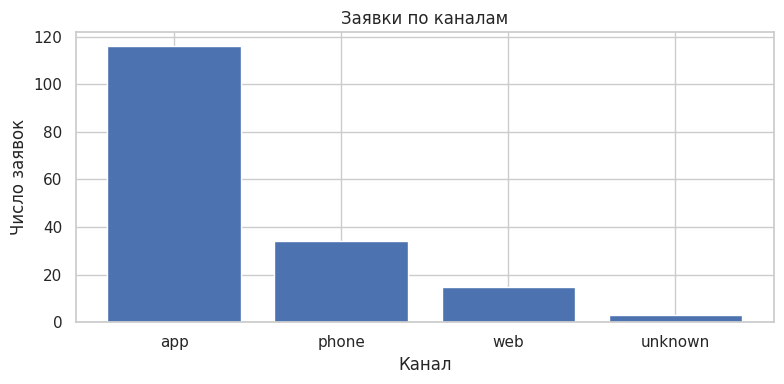

In [6]:
counts = joined["channel"].value_counts()
display(counts)
plt.figure(figsize=(8, 4))
plt.bar(counts.index, counts.values)
plt.title("Заявки по каналам")
plt.xlabel("Канал")
plt.ylabel("Число заявок")
plt.tight_layout()
plt.show()


## 3. Гистограмма длительности
Какие длительности встречаются чаще? `bins` — количество интервалов (корзин), не число минут. Поменяйте 10 на 6 и 15: форма картинки изменится, исходные поездки и медиана — нет.

Медиана, мин: 30.2


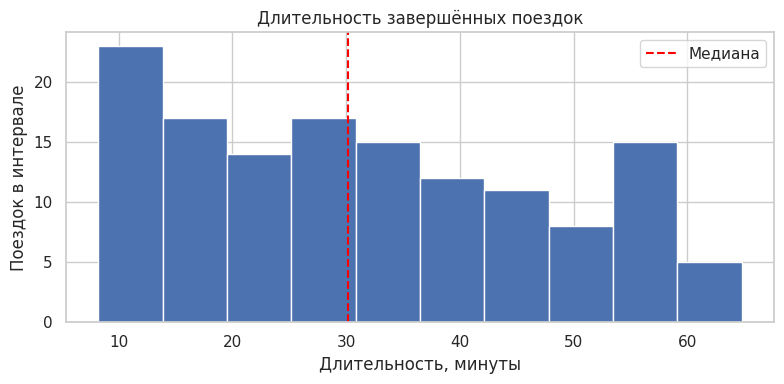

In [7]:
median_time = durations.median()
plt.figure(figsize=(8, 4))
plt.hist(durations, bins=10, edgecolor="white")
plt.axvline(median_time, color="red", linestyle="--", label="Медиана")
plt.title("Длительность завершённых поездок")
plt.xlabel("Длительность, минуты")
plt.ylabel("Поездок в интервале")
plt.legend()
plt.tight_layout()
plt.show()
print("Медиана, мин:", median_time)


## 4. Бонус: доля поездок не дольше 30 минут
Сначала обычный подсчёт, затем ECDF. ECDF показывает долю известных длительностей, не превышающих X. Этот раздел можно пройти после основной практики.

Не дольше 30 минут, %: 49.6


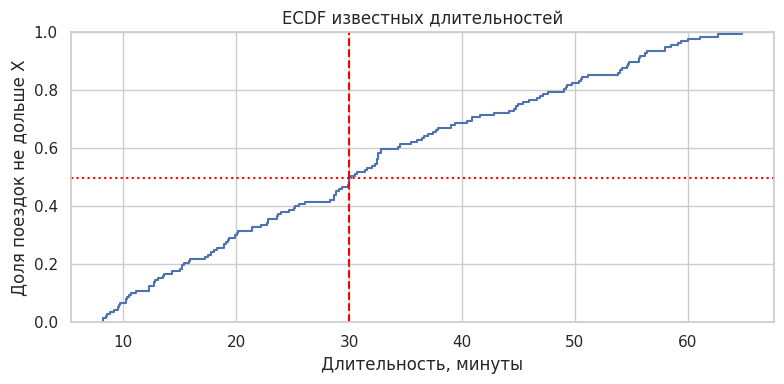

In [8]:
short_trips = durations[durations <= 30]
share = len(short_trips) / len(durations)
print("Не дольше 30 минут, %:", round(share * 100, 1))
plt.figure(figsize=(8, 4))
sns.ecdfplot(x=durations)
plt.axvline(30, color="red", linestyle="--")
plt.axhline(share, color="red", linestyle=":")
plt.xlabel("Длительность, минуты")
plt.ylabel("Доля поездок не дольше X")
plt.title("ECDF известных длительностей")
plt.tight_layout()
plt.show()


## 5. Мини-практика A
1. Возьмите `completed["fare_kzt"].dropna()`.
2. Покажите число известных оплат и медиану.
3. Постройте гистограмму стоимости с подписью «тенге» и линией медианы.
4. Сравните `bins=6` и `bins=15`.
5. Запишите два наблюдения с числами и одно ограничение. Можно скопировать код раздела 3 и заменить столбец.

In [9]:
# Напишите своё решение здесь.


## 6. Сравнение зон
Сравниваем одновременно размер группы, медиану и разброс. Boxplot: коробка содержит центральные 50% значений, линия внутри — медиана. Усы не обязательно минимум/максимум; отдельные точки не обязательно ошибки.

,count,median,mean
zone,,,
Вокзал,29,28.8,29.5
Деловой район,16,25.6,29.2
Жилой район,38,28.8,30.4
Неизвестная зона,1,31.4,31.4
Университет,27,30.7,32.3
Центр,26,36.8,37.4


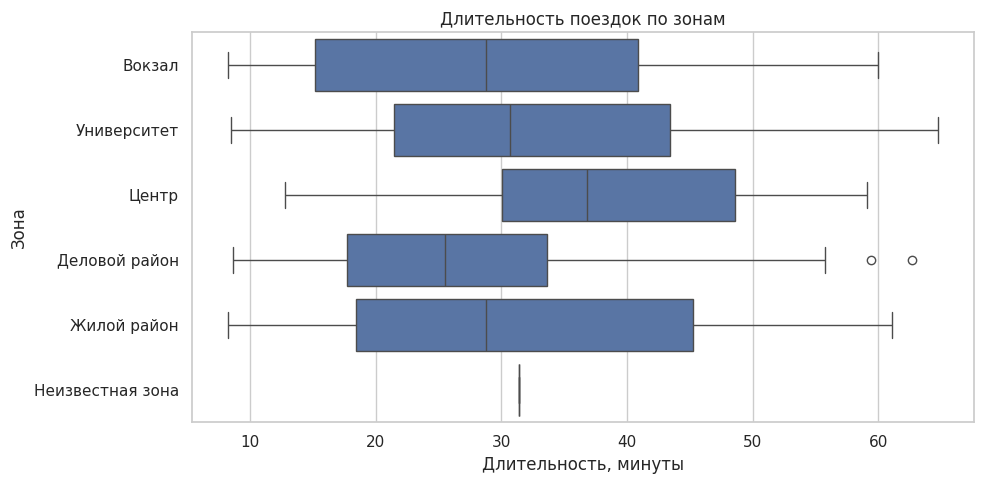

In [10]:
zone_summary = completed.groupby("zone")["duration_min"].agg(["count", "median", "mean"])
display(zone_summary.round(1))
plt.figure(figsize=(10, 5))
sns.boxplot(data=completed, x="duration_min", y="zone")
plt.title("Длительность поездок по зонам")
plt.xlabel("Длительность, минуты")
plt.ylabel("Зона")
plt.tight_layout()
plt.show()


## 7. Scatter: две числовые величины
Одна точка — одна поездка. По горизонтали расстояние, по вертикали время. `alpha` — непрозрачность от 0 до 1; маленькое значение помогает увидеть наложение точек.

Полных пар: 137


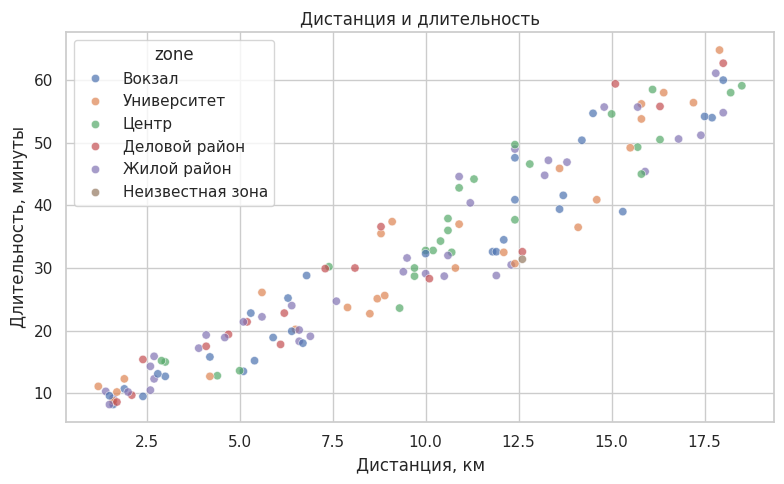

In [11]:
pairs = completed.dropna(subset=["distance_km", "duration_min"])
plt.figure(figsize=(8, 5))
sns.scatterplot(data=pairs, x="distance_km", y="duration_min", hue="zone", alpha=0.7)
plt.title("Дистанция и длительность")
plt.xlabel("Дистанция, км")
plt.ylabel("Длительность, минуты")
plt.tight_layout()
plt.show()
print("Полных пар:", len(pairs))


## Корреляции Pearson и Spearman
Pearson измеряет линейную связь, Spearman — согласованное изменение рангов. Диапазон от −1 до 1. Нулевая Pearson не исключает нелинейной зависимости. Связь не доказывает причину.

In [12]:
pearson = pairs["distance_km"].corr(pairs["duration_min"], method="pearson")
spearman = pairs["distance_km"].corr(pairs["duration_min"], method="spearman")
print("Pearson:", round(pearson, 3))
print("Spearman:", round(spearman, 3))


Pearson: 0.956
Spearman: 0.961


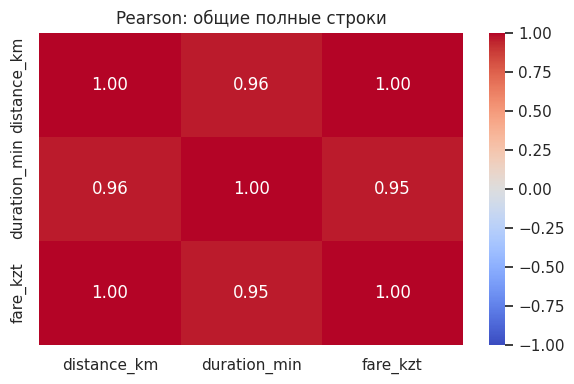

In [13]:
complete_numbers = numbers.dropna()
correlations = complete_numbers.corr()
plt.figure(figsize=(6, 4))
sns.heatmap(correlations, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Pearson: общие полные строки")
plt.tight_layout()
plt.show()


## 8. Доля отмен: правильный знаменатель
Берём ВСЕ заявки, не только завершённые. Доля отмен зоны = отмены этой зоны / все заявки этой зоны × 100. Булевы True/False при суммировании считаются как 1/0.

In [14]:
report_data = joined.copy()
report_data["cancelled"] = report_data["status"] == "cancelled"
requests = report_data.groupby("zone").size()
cancelled = report_data.groupby("zone")["cancelled"].sum()
report = pd.DataFrame({"requests": requests, "cancelled": cancelled})
report["cancel_pct"] = report["cancelled"] / report["requests"] * 100
display(report.round(1))


,requests,cancelled,cancel_pct
zone,,,
Вокзал,36,6,16.7
Деловой район,22,6,27.3
Жилой район,46,7,15.2
Неизвестная зона,1,0,0.0
Университет,33,6,18.2
Центр,30,4,13.3


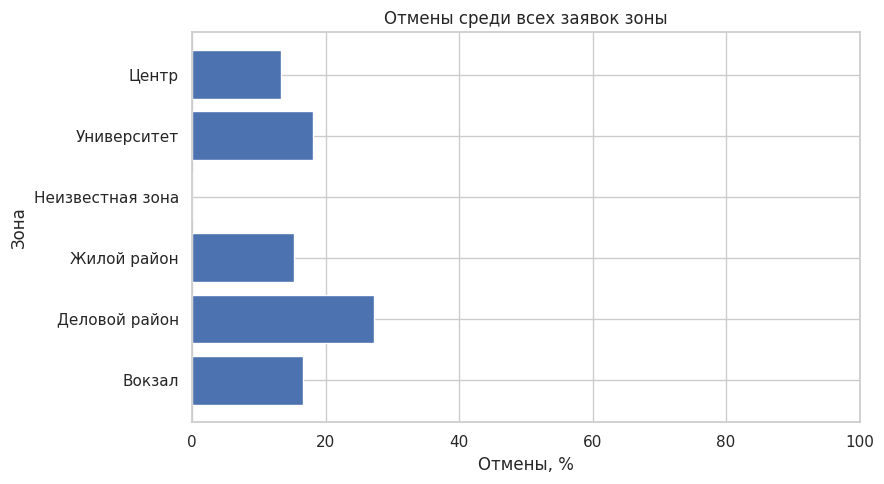

In [15]:
plt.figure(figsize=(9, 5))
plt.barh(report.index, report["cancel_pct"])
plt.xlim(0, 100)
plt.xlabel("Отмены, %")
plt.ylabel("Зона")
plt.title("Отмены среди всех заявок зоны")
plt.tight_layout()
plt.savefig(output / "cancellations.png", dpi=150)
plt.show()


## 9. Временной график
Сколько заявок за каждый день? Даты идут в хронологическом порядке. Ровная линия здесь отражает учебный генератор, а не доказанную стабильность спроса.

date
2026-10-05    24
2026-10-06    24
2026-10-07    24
2026-10-08    24
2026-10-09    24
2026-10-10    24
2026-10-11    24
dtype: int64

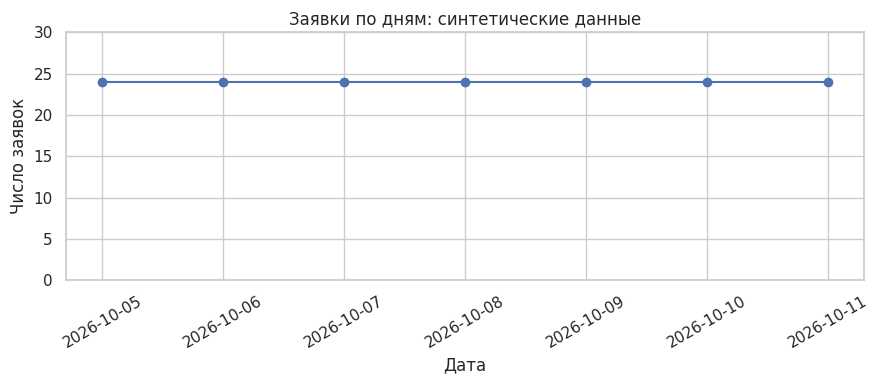

In [16]:
daily_data = joined.copy()
daily_data["date"] = daily_data["requested_at"].dt.date
daily = daily_data.groupby("date").size()
display(daily)
plt.figure(figsize=(9, 4))
plt.plot(daily.index, daily.values, marker="o")
plt.ylim(0, 30)
plt.xticks(rotation=30)
plt.xlabel("Дата")
plt.ylabel("Число заявок")
plt.title("Заявки по дням: синтетические данные")
plt.tight_layout()
plt.show()


## Бонус: интерактивный HTML
Можно пропустить. Plotly позволяет наводить курсор на точки. Если библиотека не установлена, ячейка сообщит об этом и не остановит основную практику.

In [17]:
try:
    import plotly.express as px
except ImportError:
    print("Бонус пропущен: установите plotly при необходимости.")
else:
    interactive = px.scatter(pairs, x="distance_km", y="duration_min", color="zone", hover_data=["trip_id", "fare_kzt"])
    interactive.write_html(output / "city_trips_interactive.html", include_plotlyjs=True)
    print("Интерактивный HTML сохранён в week04_outputs.")


Интерактивный HTML сохранён в week04_outputs.


## 10. Самостоятельный мини-отчёт
1. Вопрос о цене и дистанции: покажите таблицу и scatter.
2. Сравните медиану оплаты по каналам, обязательно покажите размер каждой группы.
3. Найдите долю завершённых **среди всех заявок каждого канала**, не долю канала среди завершённых.
4. Измените один параметр: bins, alpha или figsize. Объясните эффект.
5. Сохраните PNG и CSV. Вывод: наблюдение с числом → ограничение → следующий вопрос.
6. Используйте ИИ для объяснения ошибки. Запишите свой запрос и одну проверку ответа по данным.

Защита: какой вопрос, почему такой график, какой знаменатель, что увидели, чего данные не доказывают. Бонус: связь дистанции и времени внутри зон, с учётом размеров групп.

In [18]:
# Ваш мини-отчёт: скопируйте короткие примеры выше и замените нужные колонки.


## Сохранение и проверка
Проверяем количество заявок и сохраняем сводку по зонам. Эти проверки полезны, но не доказывают отсутствие любой возможной ошибки.

In [19]:
assert trips["trip_id"].is_unique
assert len(joined) == len(trips)
assert report["requests"].sum() == len(joined)
assert report["cancelled"].sum() == (joined["status"] == "cancelled").sum()
report.to_csv(output / "zone_report.csv", encoding="utf-8-sig")
print("Результаты сохранены в папке:", output.resolve())


Результаты сохранены в папке: /tmp/w4_run_student/week04_outputs
